Klasteryzacja

In [21]:
import numpy as np
import kmedoids
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, silhouette_samples
import pandas as pd

In [15]:
D = pd.read_csv('modified_data/DTW.csv', index_col=0) 
kraje = D.index  
diss = D.to_numpy() 
print(diss.shape)

(138, 138)


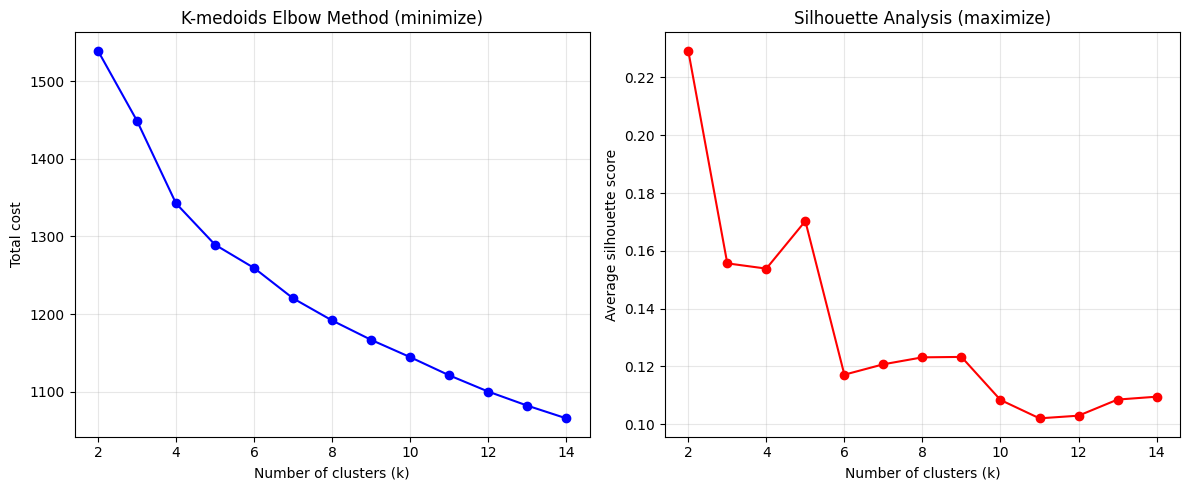

K-medoids evaluation results:
     k         cost  silhouette
0    2  1539.386930    0.229274
1    3  1449.123439    0.155646
2    4  1342.611326    0.153825
3    5  1289.332010    0.170293
4    6  1259.358105    0.117094
5    7  1220.209080    0.120701
6    8  1191.691427    0.123104
7    9  1166.691553    0.123248
8   10  1144.433430    0.108351
9   11  1120.994478    0.101982
10  12  1100.044419    0.102904
11  13  1081.957659    0.108480
12  14  1065.543996    0.109477


In [65]:
seed = 42  
def evaluate_kmedoids_clustering(data, k_range=range(2, 15)):

    results = []
    
    for k in k_range:
        # Fit k-medoids (FasterPAM algorithm)
        result = kmedoids.fasterpam(data, k, random_state=seed)
        
        labels = result.labels
        
        # Calculate metrics
        cost = result.loss  # Total cost (sum of distances to medoids)
        silhouette_avg = silhouette_score(D, labels, metric='precomputed')
        
        results.append({
            'k': k,
            'cost': cost,
            'silhouette': silhouette_avg
        })
    
    return pd.DataFrame(results)

# Evaluate k-medoids clustering
X = D.values
kmedoids_results = evaluate_kmedoids_clustering(X)

# Create evaluation plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Elbow plot
ax1.plot(kmedoids_results['k'], kmedoids_results['cost'], 'bo-')
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Total cost')
ax1.set_title('K-medoids Elbow Method (minimize)')
ax1.grid(True, alpha=0.3)

# Silhouette plot
ax2.plot(kmedoids_results['k'], kmedoids_results['silhouette'], 'ro-')
ax2.set_xlabel('Number of clusters (k)')
ax2.set_ylabel('Average silhouette score')
ax2.set_title('Silhouette Analysis (maximize)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('attachments/kmedoids_evaluation.png', dpi=300)
plt.show()

print("K-medoids evaluation results:")
print(kmedoids_results)

bardoz niski silhouete - do rozwazenia zmiana sposobu z-score

In [52]:
for i in kmedoids_results['k'].index[:-1]:
    print(kmedoids_results['k'][i])
    print(kmedoids_results['cost'][i+1] - kmedoids_results['cost'][i])

2
-90.26349095600995
3
-106.5121126461097
4
-53.27931615603438
5
-29.973904386131608
6
-39.14902592570229
7
-28.5176522319382
8
-24.999873891253173
9
-22.258123803484523
10
-23.438951192204968
11
-20.9500592102861
12
-18.08676000116475
13
-16.413663607131866


5 klastrow na podstawie sillhoutete i elbow

Stabilnosc

In [60]:
from sklearn.metrics import adjusted_rand_score

def stability_ari(dist_matrix, original_labels, k, n_iterations=100, frac=0.8, seed=42):
    rng = np.random.default_rng(seed)
    n = dist_matrix.shape[0]
    ari_scores = []

    for i in range(n_iterations):
        idx = rng.choice(n, size=int(frac * n), replace=False)             # losujemy 80% krajów bez zwracania
        sub = dist_matrix[np.ix_(idx, idx)]                                 # podmacierz: te kraje × te kraje
        new_labels = kmedoids.fasterpam(sub, k, random_state=seed).labels   # k-medoids na podmacierzy
        ari = adjusted_rand_score(original_labels[idx], new_labels)         # zgodność z oryginalnym podziałem
        ari_scores.append(ari)

    return np.array(ari_scores)

In [61]:
stability_results = []

for k in range(2, 11):
    original_labels = kmedoids.fasterpam(X, k, random_state=42).labels   # podział na pełnych danych dla tego k
    ari_scores = stability_ari(X, original_labels, k=k)                   # 100 powtórzeń na 80% krajów
    stability_results.append({
        'k': k,
        'ari_mean': ari_scores.mean(),
        'ari_std': ari_scores.std()
    })

stability_results = pd.DataFrame(stability_results)
print(stability_results)

    k  ari_mean   ari_std
0   2  0.919436  0.078873
1   3  0.500955  0.155502
2   4  0.838402  0.154568
3   5  0.829249  0.127956
4   6  0.664603  0.144623
5   7  0.718706  0.160861
6   8  0.710827  0.149936
7   9  0.688357  0.131222
8  10  0.661421  0.106260


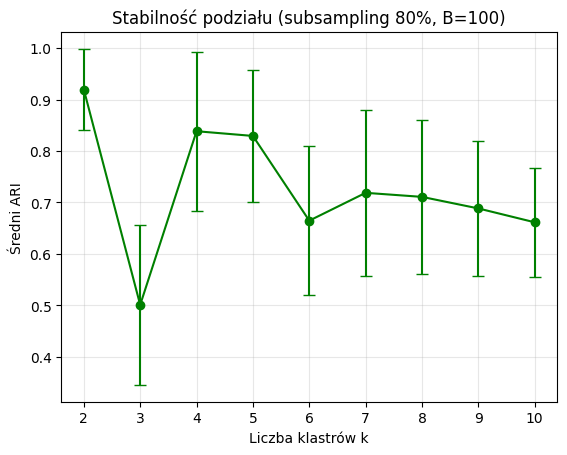

In [63]:
plt.errorbar(stability_results['k'], stability_results['ari_mean'],
             yerr=stability_results['ari_std'], fmt='go-', capsize=4)
plt.xlabel('Liczba klastrów k')
plt.ylabel('Średni ARI')
plt.title('Stabilność podziału (subsampling 80%, B=100)')
plt.grid(True, alpha=0.3)
plt.savefig('attachments/stability_plot.png', dpi=300)
plt.show()